Dataset:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   Pedigree  Age  Outcome  
0     0.627   50        1  
1     0.351   31        0  
2     0.672   32        1  
3     0.167   21        0  
4     2.288   33        1  

Confusion Matrix:
[[83 17]
 [21 33]]

Model Evaluation:
Accuracy : 0.7532
Error Rate: 0.2468
Precision: 0.66
Recall   : 0.6111


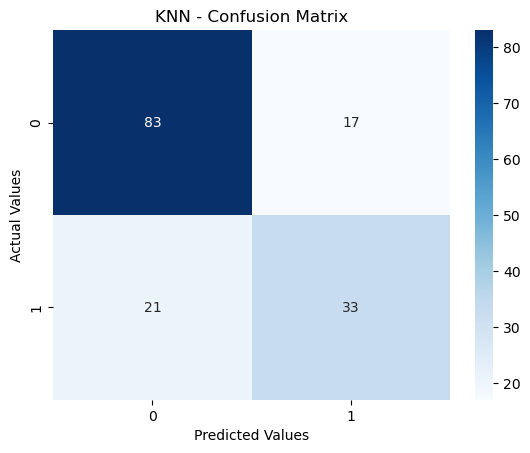

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix, accuracy_score,
    precision_score, recall_score
)

# 1. Load dataset
df = pd.read_csv("diabetes.csv")

print("Dataset:")
print(df.head())

# 2. Handle invalid zero values
columns = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

for col in columns:
    df[col] = df[col].replace(0, np.nan)
    df[col] = df[col].fillna(df[col].median())

# 3. Separate features and target
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

# 4. Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 5. Feature scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 6. Create and train KNN model
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

# 7. Make predictions
y_pred = knn.predict(X_test)

# 8. Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

# 9. Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
error_rate = 1 - accuracy
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)

print("\nModel Evaluation:")
print("Accuracy :", round(accuracy, 4))
print("Error Rate:", round(error_rate, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))

# 10. Visualize confusion matrix
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("KNN - Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()
